# 01 — Data collection (simulated)

**This is not real store data.** We generated it so we already know true demand. That lets us *see* the censoring problem. It does not prove a method works in a shop.

Rule:

`sales = min(true_demand, opening_stock)`

Two files:

- `data/raw/observed_daily.csv` — what the store could log
- `data/raw/with_ground_truth.csv` — plus hidden demand (**evaluation only**, never a training feature)


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(
    p for p in (Path("."), Path(".."))
    if (p / "data" / "raw" / "observed_daily.csv").exists()
)
observed = pd.read_csv(ROOT / "data" / "raw" / "observed_daily.csv")
truth = pd.read_csv(ROOT / "data" / "raw" / "with_ground_truth.csv")

print("observed", observed.shape)
print("truth   ", truth.shape)
print("data_source values:", observed["data_source"].unique())
print("products:", sorted(observed["product"].unique()))
print("date range:", observed["date"].min(), "→", observed["date"].max())

observed (1200, 12)
truth    (1200, 16)
data_source values: ['simulated']
products: ['Biscuits', 'Bread', 'Eggs', 'Milk', 'Oil', 'Rice', 'Soap', 'Sugar', 'Tea', 'Yogurt']
date range: 2025-09-01 → 2025-12-29


## What a store would actually record

`pd.read_csv` loads the file into a DataFrame (a table). `head()` shows the first rows. There is **no** `true_demand` column here.


In [2]:
observed.head(8)

,date,store,product,opening_stock,sales,closing_stock,price,promo,holiday,delivery_qty,stockout_flag,data_source
0,2025-09-01,store_01,Milk,40,21,19,55,0,0,0,0,simulated
1,2025-09-02,store_01,Milk,19,15,4,55,0,0,0,0,simulated
2,2025-09-03,store_01,Milk,54,26,28,55,0,0,50,0,simulated
3,2025-09-04,store_01,Milk,28,20,8,55,0,0,0,0,simulated
4,2025-09-05,store_01,Milk,58,27,31,55,0,0,50,0,simulated
5,2025-09-06,store_01,Milk,31,28,3,55,0,0,0,0,simulated
6,2025-09-07,store_01,Milk,3,3,0,55,0,0,0,1,simulated
7,2025-09-08,store_01,Milk,50,26,24,55,0,0,50,0,simulated


## The hidden column

Compare `true_demand` vs `sales` on Biscuits. When stock is 8 and 14 people wanted biscuits, the log still says `sales = 8`.


In [3]:
biscuits = truth[truth["product"] == "Biscuits"][
    ["date", "opening_stock", "true_demand", "sales", "closing_stock", "is_censored"]
]
biscuits.head(14)

,date,opening_stock,true_demand,sales,closing_stock,is_censored
480,2025-09-01,8,14,8,0,1
481,2025-09-02,0,8,0,0,1
482,2025-09-03,0,5,0,0,1
483,2025-09-04,16,10,10,6,0
484,2025-09-05,6,9,6,0,1
485,2025-09-06,0,13,0,0,1
486,2025-09-07,16,8,8,8,0
487,2025-09-08,8,4,4,4,0
488,2025-09-09,4,13,4,0,1
489,2025-09-10,16,8,8,8,0


Read Sep 1–3 like this:

| date | stock | true demand | recorded sales |
| --- | ---: | ---: | ---: |
| Sep 1 | 8 | 14 | 8 |
| Sep 2 | 0 | 8 | 0 |
| Sep 3 | 0 | 5 | 0 |

A naive model that only sees sales learns `8, 0, 0` and can conclude demand collapsed. It did not.


In [4]:
summary = (
    truth.groupby("product", as_index=False)
    .agg(
        days=("date", "count"),
        sales_units=("sales", "sum"),
        true_demand_units=("true_demand", "sum"),
        lost_sales_units=("lost_sales", "sum"),
        censored_days=("is_censored", "sum"),
        stockout_flag_days=("stockout_flag", "sum"),
    )
    .sort_values("censored_days", ascending=False)
)
summary

,product,days,sales_units,true_demand_units,lost_sales_units,censored_days,stockout_flag_days
0,Biscuits,120,584,1158,574,80,80
9,Yogurt,120,1044,1387,343,55,55
8,Tea,120,401,527,126,34,34
3,Milk,120,2567,3021,454,33,33
6,Soap,120,334,412,78,31,31
2,Eggs,120,1660,1893,233,30,30
4,Oil,120,569,648,79,23,23
7,Sugar,120,807,899,92,23,23
5,Rice,120,781,804,23,8,8
1,Bread,120,2437,2456,19,5,5


## One chart: sales is not demand

If sales drop whenever inventory hits zero, you are looking at **censoring**, not a demand crash.


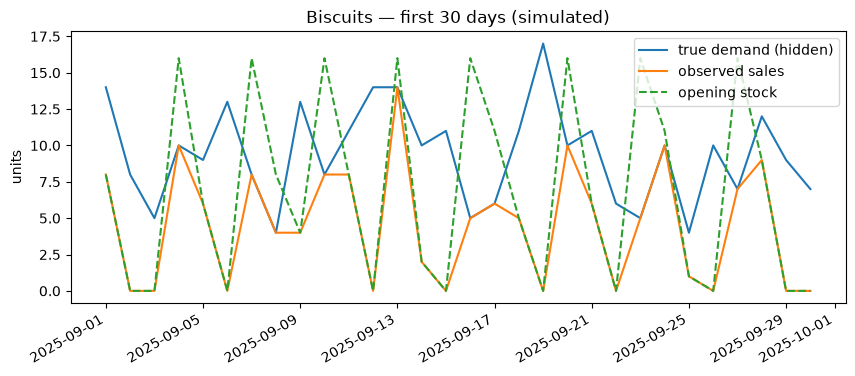

In [5]:
plot_df = biscuits.copy()
plot_df["date"] = pd.to_datetime(plot_df["date"])
plot_df = plot_df.head(30)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(plot_df["date"], plot_df["true_demand"], label="true demand (hidden)")
ax.plot(plot_df["date"], plot_df["sales"], label="observed sales")
ax.plot(plot_df["date"], plot_df["opening_stock"], label="opening stock", linestyle="--")
ax.set_title("Biscuits — first 30 days (simulated)")
ax.set_ylabel("units")
ax.legend()
fig.autofmt_xdate()
plt.show()

## Leakage rule (write this down)

Do **not** train on `true_demand`, `lost_sales`, `is_censored`, or `demand_mean`. A real store never sees those. We keep them so later we can test whether a stockout-aware model recovers demand better than one trained on `sales` alone.

Next phase: pandas on *this* table (missing values, dtypes, duplicates) — still no ML.
